In [2]:
#bash -c 'for f in gen9monotype-matchup_chart-0.txt gen9monotype-matchup_chart-1500.txt gen9monotype-matchup_chart-1630.txt gen9monotype-matchup_chart-1760.txt gen9nationaldexmonotype-matchup_chart-0.txt gen9nationaldexmonotype-matchup_chart-1500.txt gen9nationaldexmonotype-matchup_chart-1630.txt gen9nationaldexmonotype-matchup_chart-1760.txt; do curl -O "https://www.smogon.com/stats/2026-03/monotype/matchupcharts/$f"; done'import gzip
import numpy as np
import matplotlib.pyplot as plt

TYPES = [
    'normal','fighting','flying','poison','ground','rock',
    'bug','ghost','steel','fire','water','grass',
    'electric','psychic','ice','dragon','dark','fairy'
]
N = len(TYPES)
type_index = {t: i for i, t in enumerate(TYPES)}

FILES = [
    'gen9monotype-matchup_chart-0.txt',
    'gen9monotype-matchup_chart-1500.txt',
    'gen9monotype-matchup_chart-1630.txt',
    'gen9monotype-matchup_chart-1760.txt',
    'gen9nationaldexmonotype-matchup_chart-0.txt',
    'gen9nationaldexmonotype-matchup_chart-1500.txt',
    'gen9nationaldexmonotype-matchup_chart-1630.txt',
    'gen9nationaldexmonotype-matchup_chart-1760.txt',
]

VAR_NAMES = [
    'gen9mono_0', 'gen9mono_1500', 'gen9mono_1630', 'gen9mono_1760',
    'gen9natdexmono_0', 'gen9natdexmono_1500', 'gen9natdexmono_1630', 'gen9natdexmono_1760',
]

In [3]:
normalized_mu_charts = []
games_charts = []

for fname in FILES:
    winrate_matrix = np.zeros((N, N))
    games_matrix   = np.zeros((N, N))

    with open(fname, 'r', encoding='utf-8') as f:
        lines = f.readlines()

    i = 0
    while i < len(lines):
        parts = [p.strip() for p in lines[i].split('|')]
        if len(parts) >= 3 and parts[1].strip() in type_index:
            row_i = type_index[parts[1].strip()]

            col_j = 0
            for cell in parts[2:]:
                cell = cell.strip()
                if cell and not cell.endswith('%') and col_j < N:
                    try:
                        games_matrix[row_i][col_j] = float(cell)
                        col_j += 1
                    except ValueError:
                        pass

            i += 1
            while i < len(lines) and lines[i].strip().startswith('+'):
                i += 1
            if i < len(lines):
                rate_parts = [p.strip() for p in lines[i].split('|')]
                col_j = 0
                for cell in rate_parts[2:]:
                    cell = cell.strip()
                    if cell.endswith('%') and col_j < N:
                        winrate_matrix[row_i][col_j] = float(cell[:-1]) / 100.0
                        col_j += 1
        i += 1

    for i in range(N):
        for j in range(i + 1, N):
            total = winrate_matrix[i][j] + winrate_matrix[j][i]
            if total > 0:
                winrate_matrix[i][j] /= total
                winrate_matrix[j][i] /= total
            else:
                winrate_matrix[i][j] = 0.5
                winrate_matrix[j][i] = 0.5
        winrate_matrix[i][i] = 0.0
    winrate_matrix = np.round(winrate_matrix, 5)
    normalized_mu_charts.append(winrate_matrix)
    games_charts.append(games_matrix)

for line in normalized_mu_charts[2]:
  for elem in line:
    print(elem, end="\t")
  print()

0.0	0.36588	0.60952	0.37353	0.49209	0.3614	0.56667	0.62278	0.43246	0.51192	0.5061	0.5994	0.61244	0.46509	0.60443	0.46428	0.49643	0.42084	
0.63412	0.0	0.3562	0.39659	0.47895	0.84193	0.69162	0.27924	0.65841	0.5631	0.53043	0.47716	0.57138	0.24197	0.64915	0.64865	0.60956	0.24178	
0.39048	0.6438	0.0	0.75176	0.63418	0.43388	0.51957	0.49689	0.5146	0.49138	0.48332	0.64361	0.52297	0.4719	0.26585	0.54281	0.54481	0.58951	
0.62647	0.60341	0.24824	0.0	0.19068	0.43456	0.57923	0.56926	0.27797	0.46811	0.4828	0.67484	0.53693	0.46556	0.55984	0.47292	0.59207	0.70886	
0.50791	0.52105	0.36582	0.80932	0.0	0.79559	0.5563	0.61323	0.5625	0.68177	0.36248	0.32752	0.72791	0.46625	0.16806	0.59974	0.36322	0.50577	
0.6386	0.15807	0.56612	0.56544	0.20441	0.0	0.60532	0.55896	0.26688	0.80985	0.41343	0.57078	0.52625	0.5486	0.70195	0.48558	0.514	0.617	
0.43333	0.30838	0.48043	0.42077	0.4437	0.39468	0.0	0.5498	0.27249	0.31175	0.42992	0.6634	0.24271	0.65497	0.80049	0.33791	0.68162	0.56555	
0.37722	0.72076	0.50311	0.43074	0

In [4]:
viability_scores = []

for m in normalized_mu_charts:
    avg_winrate = np.array([
        np.mean([m[t][j] for j in range(N) if j != t])
        for t in range(N)
    ])
    scores = {
        TYPES[t1]: sum(avg_winrate[t2] * m[t1][t2] for t2 in range(N) if t2 != t1)
        for t1 in range(N)
    }
    viability_scores.append(dict(sorted(scores.items(), key=lambda x: x[1], reverse=True)))

for t, s in viability_scores[2].items():
    print(f"  {t:<12} {s:.4f}")

  steel        4.6551
  flying       4.4598
  ground       4.4554
  fighting     4.4277
  dark         4.4187
  dragon       4.3859
  rock         4.3297
  water        4.2860
  fire         4.2306
  normal       4.2284
  ghost        4.2205
  psychic      4.2195
  poison       4.2062
  fairy        4.2022
  ice          4.0669
  bug          3.9956
  grass        3.7957
  electric     3.6517


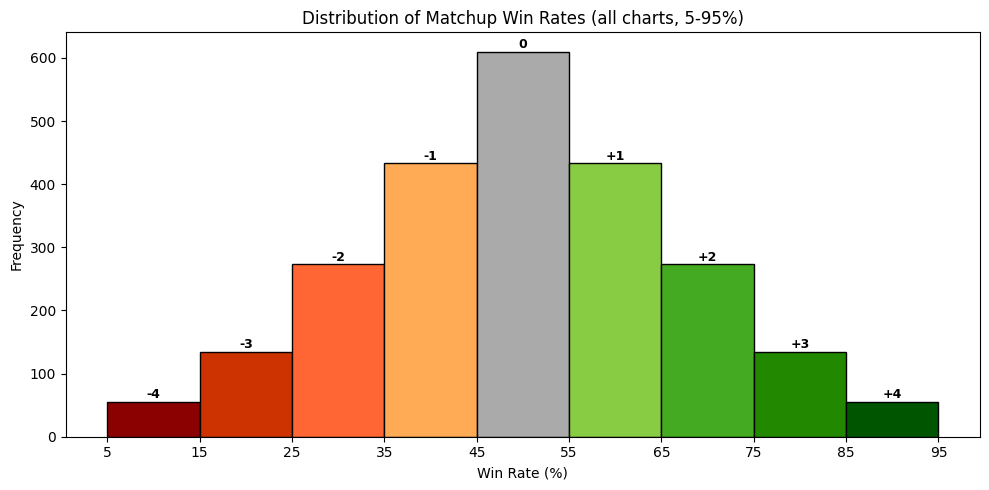

In [7]:
BIN_EDGES  = [5, 15, 25, 35, 45, 55, 65, 75, 85, 95]
BIN_SCORES = ['-4', '-3', '-2', '-1', '0', '+1', '+2', '+3', '+4']
BIN_COLORS = ['#8B0000','#CC3300','#FF6633','#FFAA55',
              '#AAAAAA','#88CC44','#44AA22','#228800','#005500']

all_winrates_pct = [
    m[i][j] * 100
    for m in normalized_mu_charts
    for i in range(N)
    for j in range(N)
    if i != j
]

fig, ax = plt.subplots(figsize=(10, 5))
counts, edges, patches = ax.hist(all_winrates_pct, bins=BIN_EDGES, edgecolor='black')
for patch, color, label, count, left, right in zip(
        patches, BIN_COLORS, BIN_SCORES, counts, BIN_EDGES[:-1], BIN_EDGES[1:]):
    patch.set_facecolor(color)
    ax.text((left + right) / 2, count + 1, label, ha='center', va='bottom',
            fontsize=9, fontweight='bold')

ax.set_xticks(BIN_EDGES)
ax.set_xlabel('Win Rate (%)')
ax.set_ylabel('Frequency')
ax.set_title('Distribution of Matchup Win Rates (all charts, 5-95%)')
plt.tight_layout()
plt.show()

In [11]:
discretized_charts = []

for m in normalized_mu_charts:
    disc = np.zeros((N, N), dtype=int)
    for i in range(N):
        for j in range(N):
            if i == j:
                disc[i][j] = 0
            else:
                pct = m[i][j] * 100
                score = -4  # default if below first bin
                for k, (lo, hi) in enumerate(zip(BIN_EDGES[:-1], BIN_EDGES[1:])):
                    if lo <= pct < hi:
                        score = BIN_SCORES[k]
                        break
                disc[i][j] = score
    discretized_charts.append(disc)
for line in discretized_charts[2]:
  for elem in line:
    print(elem, end=" ")
  print()

0 -1 1 -1 0 -1 1 1 -1 0 0 1 1 0 1 0 0 -1 
1 0 -1 -1 0 3 2 -2 2 1 0 0 1 -3 1 1 1 -3 
-1 1 0 3 1 -1 0 0 0 0 0 1 0 0 -2 0 0 1 
1 1 -3 0 -3 -1 1 1 -2 0 0 2 0 0 1 0 1 2 
0 0 -1 3 0 3 1 1 1 2 -1 -2 2 0 -3 1 -1 0 
1 -3 1 1 -3 0 1 1 -2 3 -1 1 0 0 2 0 0 1 
-1 -2 0 -1 -1 -1 0 0 -2 -2 -1 2 -3 2 3 -2 2 1 
-1 2 0 -1 -1 -1 0 0 0 0 0 1 3 1 1 0 -1 -1 
1 -2 0 2 -1 2 2 0 0 -2 -1 0 -2 2 3 1 0 2 
0 -1 0 0 -2 -3 2 0 2 0 -1 3 -1 -1 2 -3 0 2 
0 0 0 0 1 1 1 0 1 1 0 -2 -2 1 -1 -1 0 1 
-1 0 -1 -2 2 -1 -2 -1 0 -3 2 0 2 1 -3 -2 -1 0 
-1 -1 0 0 -2 0 3 -3 2 1 2 -2 0 -3 -3 -3 0 -1 
0 3 0 0 0 0 -2 -1 -2 1 -1 -1 3 0 2 0 -3 0 
-1 -1 2 -1 3 -2 -3 -1 -3 -2 1 3 3 -2 0 2 0 -2 
0 -1 0 0 -1 0 2 0 -1 3 1 2 3 0 -2 0 -1 -1 
0 -1 0 -1 1 0 -2 1 0 0 0 1 0 3 0 1 0 -1 
1 3 -1 -2 0 -1 -1 1 -2 -2 -1 0 1 0 2 1 1 0 


In [20]:
z = 1.96
conf_int = []

for norm_m, games_m in zip(normalized_mu_charts, games_charts):
    ci = [[None] * N for _ in range(N)]
    for i in range(N):
        for j in range(N):
            if i == j:
                ci[i][j] = (0.0, 0.0)
            else:
                n = (games_m[i][j] + games_m[j][i]) / 2
                p = norm_m[i][j]
                if n <= 0:
                    ci[i][j] = (0.0, 0.0)
                else:
                    denom  = 1 + z**2 / n
                    center = (p + z**2 / (2 * n)) / denom
                    margin = (z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))) / denom
                    ci[i][j] = (max(0.0, center - margin), min(1.0, center + margin))
    ci = np.round(ci, 5)
    conf_int.append(ci)


for line in conf_int[2]:
  for elem in line:
    print(str(elem[0])+"\t"+str(elem[1]), end="\t")
  print()

0.0	0.0	0.23325	0.52253	0.43528	0.75968	0.22827	0.54584	0.33981	0.64585	0.17064	0.60886	0.38467	0.7323	0.47433	0.75129	0.29575	0.5803	0.33324	0.68761	0.36717	0.6441	0.37491	0.7887	0.33324	0.83323	0.26297	0.67937	0.33833	0.82034	0.3447	0.58811	0.34653	0.64697	0.25264	0.60967	
0.47747	0.76675	0.0	0.0	0.25497	0.47215	0.28707	0.51756	0.37968	0.57992	0.67478	0.93185	0.57214	0.78998	0.19756	0.37875	0.55444	0.7491	0.43463	0.68363	0.44408	0.615	0.31002	0.64958	0.35267	0.76536	0.13012	0.40519	0.47939	0.78803	0.56627	0.72304	0.50517	0.7048	0.15326	0.3597	
0.24032	0.56472	0.52785	0.74503	0.0	0.0	0.60543	0.85667	0.51592	0.73821	0.26536	0.61922	0.38419	0.65214	0.38476	0.60933	0.39092	0.63652	0.35086	0.63328	0.38639	0.58153	0.47144	0.78524	0.27665	0.7586	0.30541	0.64488	0.13992	0.4463	0.4553	0.62775	0.43465	0.65076	0.44604	0.71921	
0.45416	0.77173	0.48244	0.71293	0.14333	0.39457	0.0	0.0	0.10239	0.32733	0.2545	0.63372	0.42246	0.7215	0.44915	0.68174	0.17717	0.40771	0.31909	0.62305	0.3728	0.59449	0.469

In [35]:
def to_score(pct):
    for k, (lo, hi) in enumerate(zip(BIN_EDGES[:-1], BIN_EDGES[1:])):
        if lo <= pct < hi:
            return BIN_SCORES[k]
    return None  # outside 5-95 range

z = 1.96
conf_int_scores = []
bool_table = []
for norm_m, games_m in zip(normalized_mu_charts, games_charts):
    ci = [[None] * N for _ in range(N)]
    ci_bool = [[None] * N for _ in range(N)]
    for i in range(N):
        for j in range(N):
            if i == j:
                ci[i][j] = (0, 0)
                ci_bool[i][j] = (False, False)
            else:
                n = (games_m[i][j] + games_m[j][i]) / 2
                p = norm_m[i][j]
                if n <= 0:
                    ci[i][j] = (0, 0)
                    ci_bool[i][j] = (False, False)
                else:
                    denom  = 1 + z**2 / n
                    center = (p + z**2 / (2 * n)) / denom
                    margin = (z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))) / denom
                    lo = max(0.0, center - margin) * 100
                    hi = min(1.0, center + margin) * 100
                    ci[i][j] = (to_score(lo), to_score(hi))
                    ci_bool[i][j] = (lo<45.0 and hi<45.0, lo>55.0 and hi>55.0)
    conf_int_scores.append(ci)
    bool_table.append(ci_bool)

for line in conf_int_scores[2]:
  for elem in line:
    print(str(elem[0])+"\t"+str(elem[1]), end="\t")
  print()
tot = []
for line in bool_table[2]:
  for elem in line:
    if(elem[0]):
      print("-1", end="\t")
    elif(elem[1]):
      print("+1", end="\t")
    else:
      print("0", end="\t")
    # print(str(elem[0])+"\t"+str(elem[1]), end="\t")
  print()

0	0	-3	0	-1	+3	-3	0	-2	+1	-3	+1	-1	+2	0	+3	-2	+1	-2	+2	-1	+1	-1	+3	-2	+3	-2	+2	-2	+3	-2	+1	-2	+1	-2	+1	
0	+3	0	0	-2	0	-2	0	-1	+1	+2	+4	+1	+3	-3	-1	+1	+2	-1	+2	-1	+1	-2	+1	-1	+3	-4	-1	0	+3	+1	+2	0	+2	-3	-1	
-3	+1	0	+2	0	0	+1	+4	0	+2	-2	+1	-1	+2	-1	+1	-1	+1	-1	+1	-1	+1	0	+3	-2	+3	-2	+1	-4	-1	0	+1	-1	+2	-1	+2	
0	+3	0	+2	-4	-1	0	0	-4	-2	-2	+1	-1	+2	-1	+2	-3	-1	-2	+1	-1	+1	0	+3	-2	+3	-2	+2	-2	+3	-1	+1	0	+2	+1	+3	
-1	+2	-1	+1	-2	0	+2	+4	0	0	+1	+4	-1	+2	0	+2	0	+2	0	+3	-2	0	-3	0	0	+4	-2	+1	-4	-2	0	+2	-2	0	-1	+1	
-1	+3	-4	-2	-1	+2	-1	+2	-4	-1	0	0	-1	+3	-1	+2	-3	-1	+1	+4	-2	+1	-2	+3	-3	+3	-2	+3	0	+4	-1	+1	-1	+2	-1	+3	
-2	+1	-3	-1	-2	+1	-2	+1	-2	+1	-3	+1	0	0	-1	+2	-3	-1	-3	0	-2	0	0	+3	-4	0	0	+3	+1	+4	-2	-1	+1	+3	-1	+2	
-3	0	+1	+3	-1	+1	-2	+1	-2	0	-2	+1	-2	+1	0	0	-1	+1	-2	+1	-1	0	-1	+2	+1	+4	-1	+2	-1	+2	-1	+1	-2	0	-2	+1	
-1	+2	-2	-1	-1	+1	+1	+3	-2	0	+1	+3	+1	+3	-1	+1	0	0	-3	-1	-2	0	-1	+2	-4	+1	0	+3	+2	+4	+1	+2	-1	+1	0	+3	
-2	+2	-2	+1	-1	+1	-1	+2	-3	0	-4	-1	0	+3	-1	+2	+1	+3	0	0	-2	0	+1	+4	-3	+1	-3	